# Diffusion models, Lecture 2: better and faster diffusion

**Problem.** Lecture 1 ended with a working generator and three complaints about it.

1. **It is slow.** Every sample needed 1,000 network calls, one after another.
2. **It cannot be steered.** We could not ask for a 7: the seed picks some digit, and we get whatever comes out.
3. **Its noise schedule wastes steps.** With the linear schedule, the image is essentially gone after about two thirds of the steps, so the last third of the process works on almost pure noise.

This lecture fixes each one, **without changing the basic recipe** of Lecture 1 (add noise with a fixed schedule, train a network to predict it). The fixes act at three different places: the **schedule** (before training), what the network is **told** (during training), and how we **sample** (after training).

**What you will learn**

1. Why the **cosine schedule** spreads the work more evenly than the linear one.
2. How to make the network **class-conditional**, so it draws the digit we ask for.
3. Why sampling uses an **exponential moving average (EMA)** of the weights.
4. How **classifier-free guidance** trades diversity for fidelity to the condition, and how to measure that trade-off.
5. How **DDIM** samples from the **same trained network** in 50 steps instead of 1,000.

**Prerequisites:** Lectures 1a and 1b ([Lecture 1a](lecture1a_forward_process.ipynb) and [Lecture 1b](lecture1b_learning_to_denoise.ipynb)): the forward equation $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$, the noise-predicting U-Net, the training loss, and the DDPM reverse step. Nothing else is assumed.

**Setup and downloads.** Run on **Kaggle with a T4 GPU and internet on**, once before class: it takes several minutes, most of it training in Section 3.

| Section | What | Download | Licence |
| --- | --- | ---: | --- |
| 2 | MNIST handwritten digits (via `torchvision`) | about 12 MB | see the dataset page (LeCun, Cortes & Burges) |
| 7 | `google/ddpm-cifar10-32`, the DDPM of Ho et al. (2020) | 143 MB | Apache-2.0 |

Sections 1–6 also run on a CPU, but training then takes much longer; set `EPOCHS = 1` to try it.

**About the saved outputs.** The outputs and the numbers quoted in the "Reading the output" notes come from one run on a Kaggle T4 GPU (PyTorch 2.11, torchvision 0.26) on 17 October 2026, except the toy EMA example in Section 3, which was added later and run on a CPU. A rerun gives slightly different numbers and different samples, even with the same seeds, because GPU arithmetic is not exactly reproducible and library versions change.

In [30]:
import copy
import math
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 0
torch.manual_seed(SEED)
DATA_DIR = Path("data")          # MNIST is downloaded here; nothing else is written to disk
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE)


def to_display(x):
    """Images in [-1, 1] -> [0, 1] for plotting. Values outside are clipped for display only."""
    return ((x.detach().float().cpu() + 1) / 2).clamp(0, 1)


def show_row(images, titles=None, size=1.6, suptitle=None):
    """One row of images, each (C, H, W) in [-1, 1]."""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(size * n, size * 1.15))
    for i, ax in enumerate(axes if n > 1 else [axes]):
        img = to_display(images[i])
        ax.imshow(img.permute(1, 2, 0).squeeze(), cmap="gray" if img.shape[0] == 1 else None, vmin=0, vmax=1)
        ax.axis("off")
        if titles:
            ax.set_title(titles[i], fontsize=9)
    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    plt.tight_layout(); plt.show()


def show_grid(images, nrow=10, title=None, size=8):
    grid = torchvision.utils.make_grid(to_display(images), nrow=nrow, padding=2, pad_value=1)
    plt.figure(figsize=(size, size * grid.shape[1] / grid.shape[2]))
    plt.imshow(grid.permute(1, 2, 0)); plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()

PyTorch 2.11.0+cu128 | torchvision 0.26.0+cu128 | device: cuda


## 1. The noise schedule: where the steps are spent

**The schedule decides how the 1,000 steps are shared out between noise levels.** A good schedule spends few of them on images that are already pure noise.

**Recap from Lecture 1a.**

| Symbol | Meaning |
| --- | --- |
| $\beta_t$ | variance of the noise added at step $t$ |
| $\alpha_t = 1 - \beta_t$ | fraction of the previous image's variance kept at step $t$ |
| $\bar\alpha_t = \prod_{i=1}^{t} \alpha_i$ | fraction of the original image's variance kept after $t$ steps |

$$x_t = \underbrace{\sqrt{\bar\alpha_t}}_{\text{image weight}}\,x_0 + \underbrace{\sqrt{1-\bar\alpha_t}}_{\text{noise weight}}\,\epsilon$$

The image weight starts at 1 and ends near 0. The schedule decides **how fast** it falls along the way.

### Linear schedule (Ho et al., 2020): the image is gone early

- **Definition.** $\beta_t$ rises in equal increments from 0.0001 at the first step to 0.02 at the last.
- **A linear $\beta_t$ does not give a linear image weight.** $\bar\alpha_t$ is a product, so every step multiplies the image weight by another factor below 1, and the factors shrink as $\beta_t$ grows. The losses compound, so the image fades fast in the first half.
- **Result.** The image weight falls below 0.1 at about $t = 673$. There $x_t \approx 0.1\,x_0 + 0.995\,\epsilon$: only a faint trace of the image is left under the noise.
- **Cost.** The remaining 327 steps, a third of the process, work on almost pure noise.

### Cosine schedule (Nichol & Dhariwal, 2021): spread the fade over the whole range

- **Definition.** Skip $\beta_t$ and define $\bar\alpha_t$ directly:

$$\bar\alpha_t = \frac{f(t)}{f(0)}, \qquad f(t) = \cos^2\!\left(\frac{t/T + s}{1 + s}\cdot\frac{\pi}{2}\right), \qquad s = 0.008, \quad T = 1000.$$

Here $t/T$ runs from 0 to 1, so the angle runs from about 0 to $\pi/2$ and $\cos^2$ falls from about 1 to 0. Dividing by $f(0)$ makes $\bar\alpha_0 = 1$ exactly.
- **Shape (remember this, not the formula).** $\bar\alpha_t$ falls slowly at both ends and roughly linearly in the middle.
- **Result.** The image weight stays above 0.1 until about $t = 935$. Only 65 of the 1,000 steps are almost pure noise, against 327 for the linear schedule.
- **The point is not less noise.** Both schedules go from a clean image to pure noise. The cosine schedule spreads the steps more evenly over the noise levels, so more of them happen where there is still an image to learn from.

**Two details in the code below.**

| Detail | What it does | Why |
| --- | --- | --- |
| Offset $s = 0.008$ | Shifts the curve slightly away from its flat start | Without it, the first step would add almost no noise ($\beta_1 \approx 2.5 \times 10^{-6}$ instead of $4 \times 10^{-5}$). Nichol and Dhariwal found that such tiny noise made $\epsilon$ hard to predict accurately. |
| Cap $\beta_t \le 0.999$ | The code recovers each step's $\beta_t = 1 - \bar\alpha_t / \bar\alpha_{t-1}$ from $f$ and caps it | It only matters at the last step: $f(T) = 0$ would give $\beta_T = 1$, so $\alpha_T = 0$, and the DDPM reverse step divides by $\sqrt{\alpha_t}$. |

**Takeaway.** The linear schedule sets the noise **per step**, and the losses compound, so the image is gone early. The cosine schedule sets the **cumulative** image weight directly, so the image fades evenly over the whole range.

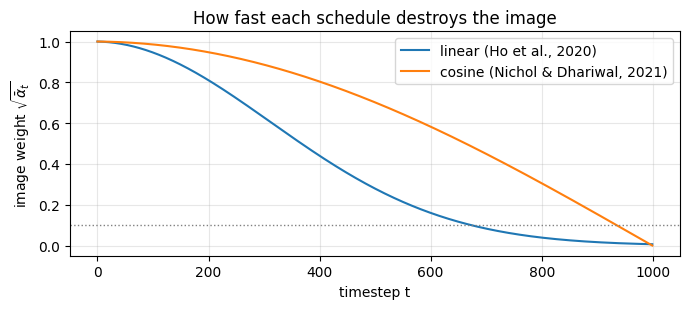

 linear: image weight below 0.5 from t = 368, below 0.1 from t = 673  ->  327 of 1000 steps are almost pure noise
 cosine: image weight below 0.5 from t = 664, below 0.1 from t = 935  ->  65 of 1000 steps are almost pure noise


In [31]:
T = 1000


def linear_alpha_bars(T, beta_start=1e-4, beta_end=0.02):
    return torch.cumprod(1 - torch.linspace(beta_start, beta_end, T), dim=0)


def cosine_alpha_bars(T, s=0.008):
    steps = torch.arange(T + 1, dtype=torch.float64)
    f = torch.cos((steps / T + s) / (1 + s) * math.pi / 2) ** 2
    betas = (1 - f[1:] / f[:-1]).clamp(max=0.999)            # per-step betas implied by f, capped as in the paper
    return torch.cumprod(1 - betas, dim=0).float()


lin, cos_ = linear_alpha_bars(T), cosine_alpha_bars(T)
plt.figure(figsize=(7, 3.2))
plt.plot(lin.sqrt(), label="linear (Ho et al., 2020)")
plt.plot(cos_.sqrt(), label="cosine (Nichol & Dhariwal, 2021)")
plt.axhline(0.1, color="grey", ls=":", lw=1)
plt.xlabel("timestep t"); plt.ylabel(r"image weight $\sqrt{\bar\alpha_t}$"); plt.legend(); plt.grid(alpha=0.3)
plt.title("How fast each schedule destroys the image"); plt.tight_layout(); plt.show()

for name, ab in (("linear", lin), ("cosine", cos_)):
    almost_noise = (ab.sqrt() < 0.1).sum().item()
    print(f"{name:>7}: image weight below 0.5 from t = {(ab.sqrt() < 0.5).nonzero()[0].item():>3}, "
          f"below 0.1 from t = {(ab.sqrt() < 0.1).nonzero()[0].item():>3}  ->  {almost_noise} of {T} steps are almost pure noise")

**Reading the plot.** The table reads off the image weight $\sqrt{\bar\alpha_t}$ of both curves at a few steps. The values follow from the schedule formulas alone, so they are the same in every run.

| Step $t$ | Linear | Cosine | What it shows |
| ---: | ---: | ---: | --- |
| 0 | 1.00 | 1.00 | clean image in both |
| 100 | 0.95 | 0.99 | both still almost clean |
| 250 | 0.72 | 0.92 | linear has lost over a quarter of the weight; cosine has barely started |
| 400 | 0.44 | 0.80 | linear is past halfway (0.5 at $t = 368$); cosine is not (0.5 at $t = 664$) |
| 550 | 0.21 | 0.64 | |
| 673 | 0.10 | 0.49 | linear reaches the dotted 0.1 line: almost pure noise from here |
| 850 | 0.03 | 0.23 | linear is flat near 0; cosine is still falling steadily |
| 935 | 0.01 | 0.10 | cosine reaches the 0.1 line |
| 999 | 0.01 | 0.00 | both pure noise |

- **Linear:** steep in the first half, then a long flat tail near 0. The flat tail is the 327 wasted steps.
- **Cosine:** a gentle start and a steady fall through the middle. The tail below 0.1 is only 65 steps.

To see the difference on an image, the next cell noises the same digit with the same noise under both schedules. It needs the data, so it loads MNIST first.

> **Download:** the next cell downloads MNIST (about 12 MB) into `data/`.

train (60000, 1, 28, 28) | test (10000, 1, 28, 28)


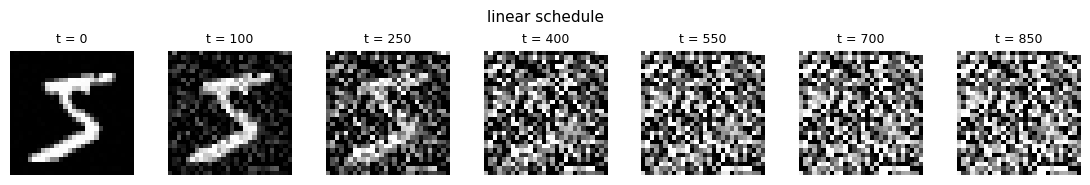

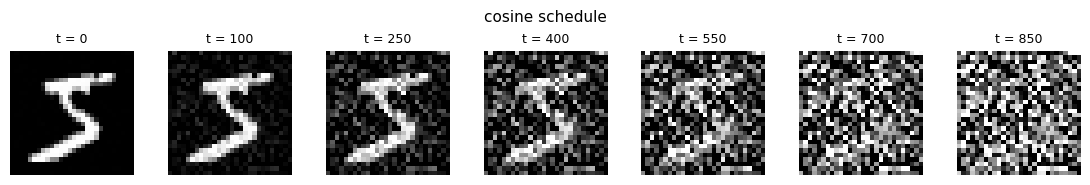

In [32]:
mnist_train = torchvision.datasets.MNIST(DATA_DIR, train=True, download=True)
mnist_test = torchvision.datasets.MNIST(DATA_DIR, train=False, download=True)
X_train = (mnist_train.data.float() / 255 * 2 - 1).unsqueeze(1).to(DEVICE)    # (60000, 1, 28, 28) in [-1, 1]
y_train = mnist_train.targets.to(DEVICE)                                       # (60000,) digit labels 0-9
X_test = (mnist_test.data.float() / 255 * 2 - 1).unsqueeze(1).to(DEVICE)
y_test = mnist_test.targets.to(DEVICE)
print("train", tuple(X_train.shape), "| test", tuple(X_test.shape))

digit = X_train[0]
torch.manual_seed(1)
noise = torch.randn_like(digit)
steps = [0, 100, 250, 400, 550, 700, 850]
for name, ab in (("linear", lin), ("cosine", cos_)):
    views = [ab[t].sqrt() * digit + (1 - ab[t]).sqrt() * noise for t in steps]
    show_row(views, [f"t = {t}" for t in steps], suptitle=f"{name} schedule")

**Reading the output.** Under the linear schedule the 5 is barely visible at $t = 250$ and gone by $t = 400$. From there on, the remaining frames are indistinguishable noise. Under the cosine schedule the 5 is still clear at $t = 400$, faint at $t = 550$, and only disappears around $t = 700$. Same number of steps, but the cosine schedule spends far fewer of them on almost pure noise.

**What we will do with this.** Changing the schedule means **retraining**, because the network learns to predict noise at the noise levels the schedule produces. To keep this lecture's comparisons clean, and to stay compatible with the published model in Section 7, the model we train below keeps the **linear** schedule of Lecture 1. Everything else in the lecture works the same with either schedule; trying cosine is an exercise at the end.

## 2. Conditioning: telling the network which digit to draw

To ask for a 7, the network must be told "7". **Conditioning** means giving the network extra input $y$ (here the class label) alongside the noisy image and the timestep:

$$\hat\epsilon = \epsilon_\theta(x_t, t, y).$$

The training data already has labels, so nothing else changes: the loss is still the mean squared error between the added noise and the predicted noise. The label is a **condition** (an input), not a prediction target. The network is not asked to classify anything; it is asked to denoise *knowing* which digit the clean image was.

**Label, class conditioning and text conditioning** are related but different things:

| | Label | Class conditioning | Text conditioning |
| --- | --- | --- | --- |
| What it is | **Data**: the class ID stored with each training image | A **technique**: give the generator the class label as an extra input | A **technique**: give the generator a text prompt as an extra input |
| The condition $y$ | — | One of a fixed set of classes (here 10 digits, plus "no label") | Any free-text prompt, e.g. "a red car on a beach" |
| Stored or passed as | An integer, here 0–9 (`torch.int64`) | That integer, used as a row index | Tokens of the prompt |
| Turned into vectors by | — | A learned embedding table: row $y$ is the class's vector | A pretrained text encoder (CLIP in Stable Diffusion): a sequence of vectors |
| Related conditions get similar vectors? | — | No: each row is learned separately, so "7" starts no closer to "1" than to "0" | Yes: the encoder captures meaning, so "car" lies near "truck" |
| How the U-Net reads it | — | Added to the timestep embedding (this lecture) | Cross-attention (Lecture 3) |
| "No condition" for guidance | — | An extra class, here label 10 | The empty prompt "" |
| In this notebook | `y_train`, `labels` | `ConditionalUNet`, `conditional_loss` | Not used; see Lecture 3 |

The same label can play opposite roles. In a **classifier** (Section 6) it is the **target**: the model maps an image to a label. In **class conditioning** it is an **input**: the model maps a noisy image, a timestep and a label to a noise prediction, and never predicts the label.

**How the label gets in.** Exactly as the timestep did in Lecture 1. A learnable **embedding table** turns each label into a vector of the same size as the timestep embedding, and the two vectors are **added**. Every block of the U-Net already receives that sum, so every layer now knows both the noise level and the digit.

**One extra label: "no label".** We add an 11th entry, index 10, meaning "unconditional". During training, each image's label is replaced by 10 with probability 0.1. The same network therefore also learns to denoise **without** knowing the digit. That costs almost nothing, and it is what makes classifier-free guidance possible in Section 4.

In [33]:
NULL_LABEL = 10          # the extra "no label" class used for classifier-free guidance
P_UNCOND = 0.1           # fraction of training labels replaced by NULL_LABEL


class TimeEmbedding(nn.Module):
    """Integer timesteps (B,) -> vectors (B, dim): sines and cosines at many frequencies, then a small MLP (as in Lecture 1)."""
    def __init__(self, dim=128):
        super().__init__()
        self.dim = dim
        self.mlp = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, dim))

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10_000) * torch.arange(half, device=t.device) / half)
        angles = t.float()[:, None] * freqs[None, :]
        return self.mlp(torch.cat([angles.sin(), angles.cos()], dim=1))


class Block(nn.Module):
    """Two 3x3 convolutions with a residual connection; the conditioning vector is added as one value per channel."""
    def __init__(self, c_in, c_out, e_dim=128):
        super().__init__()
        self.conv1 = nn.Sequential(nn.GroupNorm(8, c_in), nn.SiLU(), nn.Conv2d(c_in, c_out, 3, padding=1))
        self.cond = nn.Linear(e_dim, c_out)
        self.conv2 = nn.Sequential(nn.GroupNorm(8, c_out), nn.SiLU(), nn.Conv2d(c_out, c_out, 3, padding=1))
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, e):
        h = self.conv1(x) + self.cond(e)[:, :, None, None]
        return self.conv2(h) + self.skip(x)


class ConditionalUNet(nn.Module):
    """The Lecture 1 U-Net plus a label embedding. Input x (B, 1, 28, 28), t (B,), y (B,) in 0..10; output (B, 1, 28, 28)."""
    def __init__(self, n_labels=11):
        super().__init__()
        self.time = TimeEmbedding(128)
        self.label = nn.Embedding(n_labels, 128)          # NEW: one learnable 128-d vector per label, including "no label"
        self.stem = nn.Conv2d(1, 32, 3, padding=1)
        self.down1, self.pool1 = Block(32, 64), nn.Conv2d(64, 64, 4, stride=2, padding=1)
        self.down2, self.pool2 = Block(64, 128), nn.Conv2d(128, 128, 4, stride=2, padding=1)
        self.mid = Block(128, 128)
        self.up2, self.dec2 = nn.ConvTranspose2d(128, 128, 4, stride=2, padding=1), Block(256, 64)
        self.up1, self.dec1 = nn.ConvTranspose2d(64, 64, 4, stride=2, padding=1), Block(128, 32)
        self.out = nn.Sequential(nn.GroupNorm(8, 32), nn.SiLU(), nn.Conv2d(32, 1, 3, padding=1))

    def forward(self, x, t, y):
        e = self.time(t) + self.label(y)                  # NEW: timestep and label embeddings are simply added
        h1 = self.down1(self.stem(x), e)
        h2 = self.down2(self.pool1(h1), e)
        m = self.mid(self.pool2(h2), e)
        d2 = self.dec2(torch.cat([self.up2(m), h2], dim=1), e)
        d1 = self.dec1(torch.cat([self.up1(d2), h1], dim=1), e)
        return self.out(d1)


torch.manual_seed(SEED)
model = ConditionalUNet().to(DEVICE)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}  (Lecture 1's model: 1,578,785; the label table adds 11 x 128)")

parameters: 1,580,193  (Lecture 1's model: 1,578,785; the label table adds 11 x 128)


## 3. Training, with an exponential moving average of the weights

The training step is Lecture 1's, with two small changes marked in the code:

- each image comes with its label, and 10% of labels are replaced by "no label";
- after every update we also update an **exponential moving average (EMA)** of the weights.

First, what an EMA is, on a simple sequence of numbers.

### What an exponential moving average is

**An EMA is a running average in which recent values count more than old ones.** It is also called an *exponentially weighted average*. It is used to:

- smooth noisy sequences, such as sensor readings or prices;
- follow a slow trend underneath fast fluctuations;
- keep running statistics in deep learning: Adam's gradient averages, BatchNorm's running mean and variance, and, in this lecture, the weights of a diffusion model.

**The update.** For a sequence $x_1, x_2, \dots$, starting from some value $v_0$:

$$v_t = d\,v_{t-1} + (1 - d)\,x_t$$

| Symbol | Meaning |
| --- | --- |
| $x_t$ | the new value at step $t$ |
| $v_t$ | the average after step $t$ |
| $d$ | the **decay**, $0 < d < 1$: the share of the old average that is kept |
| $1 - d$ | the share given to the new value |

Many textbooks call the decay $\beta$. We write $d$ because $\beta_t$ already means the noise schedule.

**Why "exponential".** Unrolling the update shows the weight each past value gets:

$$v_t = (1-d)\,x_t + (1-d)\,d\,x_{t-1} + (1-d)\,d^2\,x_{t-2} + \dots + d^{\,t}\,v_0$$

- A value $k$ steps old has weight $(1-d)\,d^{\,k}$: each step back multiplies its weight by $d$.
- With $d = 0.9$: weight 0.1 for the newest value, 0.09 one step back, 0.035 ten steps back, 0.012 twenty steps back.
- No value is ever dropped; old values just fade.

**Effect of $d$.** A rule of thumb: the EMA averages roughly the last $1/(1-d)$ values. After that many steps a value's weight has fallen to about 37% ($\approx 1/e$) of the newest value's weight, because $d^{\,1/(1-d)} \approx e^{-1}$.

| $d$ | Averages roughly the last | Behaviour |
| ---: | ---: | --- |
| 0.5 | 2 values | follows almost every jump; little smoothing |
| 0.9 | 10 values | smooth, follows changes quickly |
| 0.98 | 50 values | very smooth, but lags behind changes |
| 0.999 | 1,000 values | what we use for the model weights below |

**The trade-off:** a larger $d$ gives a smoother average but **lags** further behind when the underlying values change.

#### Starting value and bias correction

**An EMA that starts at $v_0 = 0$ is too small in its early steps, because part of its weight still sits on that starting 0. Bias correction divides by the total weight the real values carry, $1 - d^{\,t}$, so the result is a proper weighted average from the first step.**

**Where the bias comes from.** Write out every term of the unrolled update, down to the first value $x_1$:

$$v_t = (1-d)\,x_t + (1-d)\,d\,x_{t-1} + \dots + (1-d)\,d^{\,t-1}\,x_1 \;+\; d^{\,t}\,v_0$$

The weights on the real values $x_1, \dots, x_t$ form a geometric series:

$$(1-d)\left(1 + d + d^2 + \dots + d^{\,t-1}\right) = (1-d)\cdot\frac{1 - d^{\,t}}{1-d} = 1 - d^{\,t}$$

So the total weight of 1 is split in two:

| Part | Weight |
| --- | --- |
| Real values $x_1, \dots, x_t$ | $1 - d^{\,t}$ |
| Starting value $v_0$ | $d^{\,t}$ |

- **With $v_0 = 0$, the $d^{\,t}$ share adds nothing.** The real values carry a total weight below 1, so the average is pulled towards 0. That is the bias.
- **For a constant input $x_t = c$, the EMA is $v_t = c\,(1 - d^{\,t})$** instead of $c$.
- **With $d = 0.98$ and $t = 10$, $1 - d^{\,t}$ is only 0.18,** so the average is about a fifth of the true level.

**The fix.** Divide by the weight the real values actually carry:

$$\hat v_t = \frac{v_t}{1 - d^{\,t}}$$

Why this is the right fix:

1. **A constant input comes out exactly right:** $\hat v_t = c\,(1-d^{\,t}) / (1-d^{\,t}) = c$ at every step.
2. **The weights now add up to 1.** Dividing each weight by their sum $1 - d^{\,t}$ makes $\hat v_t$ a true weighted average of $x_1, \dots, x_t$, with the newest value weighted most.
3. **The estimate is unbiased.** If the $x_t$ are noisy samples with a constant mean $\mu$, then $\mathbb{E}[v_t] = \mu\,(1 - d^{\,t})$ but $\mathbb{E}[\hat v_t] = \mu$. This is where the name "bias correction" comes from.

**The correction fades by itself.** As $t$ grows, $d^{\,t} \to 0$, so $1 - d^{\,t} \to 1$ and $\hat v_t \approx v_t$. The larger $d$ is, the longer the correction matters. Adam uses it for both of its gradient averages.

**Our training code does not need it.** `ema_model` starts as a copy of the model's weights, not as zeros. Its $d^{\,t}$ share sits on real weights, so dividing by $1 - d^{\,t}$ would wrongly inflate them. The starting value still fades only as $d^{\,t}$, though: after the 2,800 updates below, at $d = 0.999$, the random initial weights still carry about 6% of the weight ($0.999^{2800} \approx 0.06$).

The next cell shows all of this on a toy sequence: a slow wave plus noise, standing in for one weight that jitters from update to update.

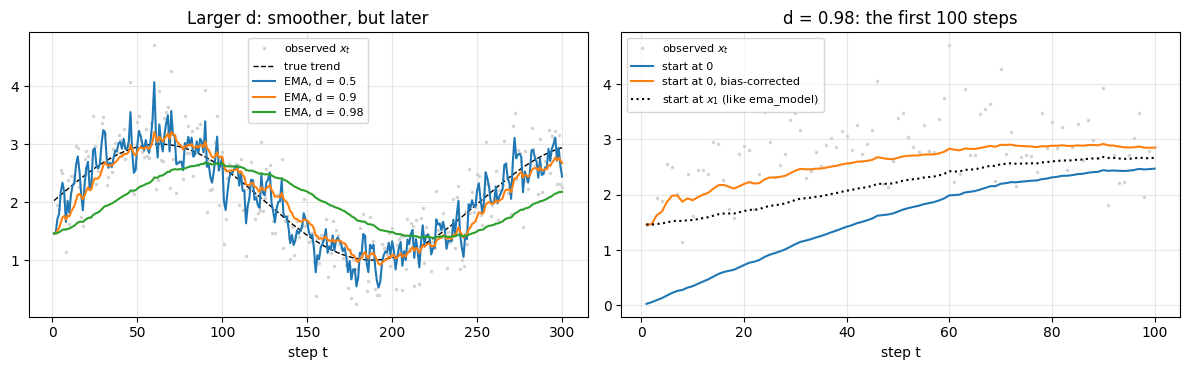

d = 0.98       t  start at 0  corrected  true trend
             1        0.03       1.46        2.02
            10        0.35       1.90        2.25
            50        1.70       2.67        2.95
           100        2.47       2.85        2.60


In [ ]:
# A fixed-seed CPU generator: the same toy sequence on any machine, whatever device the model uses.
g = torch.Generator().manual_seed(0)
n = 300
# Step numbers t = 1, ..., 300, shape (300,).
steps = torch.arange(1, n + 1)
# The slow change we want the average to follow: a wave between 1 and 3, one full cycle in about 250 steps.
trend = 2 + torch.sin(steps / 40)
# What we observe: the trend plus Gaussian jitter with standard deviation 0.5, shape (300,).
x = trend + 0.5 * torch.randn(n, generator=g)


def ema_sequence(x, d, v0):
    """Apply v_t = d * v_{t-1} + (1 - d) * x_t along the sequence x, starting from v0. Returns all v_t, shape (len(x),)."""
    # v holds the running average, starting at v0 (a number or a 0-d tensor); out collects v_1, ..., v_n.
    v, out = torch.as_tensor(v0, dtype=x.dtype), []
    # One update per observed value, in order: each v_t needs the previous v_(t-1).
    for x_t in x:
        # Keep the share d of the old average and give the new value the share 1 - d.
        v = d * v + (1 - d) * x_t
        out.append(v)
    # A list of n zero-dimensional tensors -> one tensor of shape (n,).
    return torch.stack(out)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
# Left panel: the observed values as grey dots and the true trend as a dashed line.
ax1.plot(steps, x, ".", color="lightgrey", ms=3, label="observed $x_t$")
ax1.plot(steps, trend, "k--", lw=1, label="true trend")
# One EMA curve per decay. All start from the first observed value x_1, as ema_model starts from the model's own weights.
for d in (0.5, 0.9, 0.98):
    ax1.plot(steps, ema_sequence(x, d, v0=x[0]), lw=1.5, label=f"EMA, d = {d}")
ax1.set_xlabel("step t"); ax1.set_title("Larger d: smoother, but later"); ax1.legend(fontsize=8); ax1.grid(alpha=0.3)

# Right panel: zoom in on the first 100 steps with d = 0.98, where the starting value matters most.
d, first = 0.98, 100
# EMA started from 0, the common textbook choice: biased towards 0 early on.
v_zero = ema_sequence(x, d, v0=0.0)
# Bias correction: divide each v_t by 1 - d^t, the total weight carried by real values after t steps (elementwise over the steps).
v_corrected = v_zero / (1 - d ** steps)
ax2.plot(steps[:first], x[:first], ".", color="lightgrey", ms=3, label="observed $x_t$")
# The three ways to start: from 0, from 0 with bias correction, and from x_1 (dotted, like ema_model).
ax2.plot(steps[:first], v_zero[:first], lw=1.5, label="start at 0")
ax2.plot(steps[:first], v_corrected[:first], lw=1.5, label="start at 0, bias-corrected")
ax2.plot(steps[:first], ema_sequence(x, d, v0=x[0])[:first], "k:", lw=1.5, label="start at $x_1$ (like ema_model)")
ax2.set_xlabel("step t"); ax2.set_title(f"d = {d}: the first {first} steps"); ax2.legend(fontsize=8); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# The same three quantities as numbers at a few steps. Index t - 1, because tensors count from 0 and steps from 1.
print(f"d = {d}    {'t':>4}{'start at 0':>12}{'corrected':>11}{'true trend':>12}")
for t in (1, 10, 50, 100):
    print(f"{'':>10}{t:>4}{v_zero[t - 1]:>12.2f}{v_corrected[t - 1]:>11.2f}{trend[t - 1]:>12.2f}")

**Reading the output.** The output shown was produced on a CPU (PyTorch 2.4). The toy sequence comes from a fixed-seed CPU generator, so a rerun should give the same plot and numbers.

**Left: the effect of $d$.**

| $d$ | What the curve does |
| ---: | --- |
| 0.5 | follows almost every jump; barely smoother than the data |
| 0.9 | smooth, and stays close to the trend |
| 0.98 | smoothest, but late: the trend peaks at $t = 63$ and this curve at $t = 90$; the trough comes at 188 and 225 |

All three start at $x_1 = 1.46$, which happens to sit below the trend, so they all start low.

**Right: the starting value, with $d = 0.98$.**

- **Start at 0:** 0.35 at $t = 10$, against a true level of 2.25. That is the bias from starting at zero. At $t = 100$ the average is still 13% below the corrected value.
- **Bias-corrected:** at the right level from the first step (at $t = 1$ it equals $x_1$). It is noisier early on, because it averages only a few values.
- **Start at $x_1$, as `ema_model` does:** no bias towards 0, but it carries the low starting value for a long time. Its weight is $0.98^{50} \approx 0.36$ after 50 steps and $0.13$ after 100. For `ema_model`, the starting value is the random initial weights.

### Why an EMA of the weights?

**The problem.** With a constant learning rate, the weights keep jumping around a good solution from batch to batch. Samples from the latest weights inherit that jitter.

**The fix.** Apply the same update to every weight after every training step, with the current weights $\theta$ as the new value $x_t$:

$$\theta_{\text{EMA}} \leftarrow d\,\theta_{\text{EMA}} + (1 - d)\,\theta, \qquad d = 0.999$$

- **It averages roughly the last $1/(1-d) = 1{,}000$ updates.**
- **The EMA copy is never trained directly.** It only follows the trained weights. We **train** the ordinary model and **sample** from the EMA copy.
- **The choice of $d$ depends on run length.** Ho et al. (2020) used $d = 0.9999$ over far longer training. For our short run, 0.999 suits better, because a longer average would still remember the poor early weights. That is the lag from the toy example.

Section 6 checks whether the EMA actually helped here.

In [ ]:
# The linear schedule of Lecture 1 (1,000 steps), kept so the model matches Lecture 1 and the published model in Section 7.
# betas: (1000,) -> the share of the previous image's variance replaced by noise at step t; the rest is kept.
betas = torch.linspace(1e-4, 0.02, T, device=DEVICE)
# alphas[t] = 1 - betas[t]: the share of the previous image's variance kept at step t.
# alphas: (1000,)
alphas = 1.0 - betas
# alpha_bars[t]: the share of the original image's variance left after step t; sqrt(alpha_bars[t]) is the image weight.
# alpha_bars: (1000,) 
alpha_bars = torch.cumprod(alphas, dim=0)


def add_noise(x0, t, noise):
    """The one-jump forward equation x_t = sqrt(alpha_bar_t) * x0 + sqrt(1 - alpha_bar_t) * noise, for a batch."""
    # One alpha_bar per image, (B,), reshaped to (B, 1, 1, 1) so that it broadcasts over the channel and the pixels.
    ab = alpha_bars[t].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise


def conditional_loss(model, x0, y):
    """Lecture 1's noise-prediction loss, with the label passed to the network. x0: (B, 1, 28, 28) in [-1, 1]; y: (B,) digits 0-9."""
    # A random timestep for every image, shape (B,): each batch practises many noise levels.
    t = torch.randint(0, T, (x0.shape[0],), device=x0.device)
    # NEW: True for about 10% of the images, shape (B,); those images are trained without their label.
    drop = torch.rand(x0.shape[0], device=x0.device) < P_UNCOND
    # NEW: where drop is True, replace the label by NULL_LABEL (10); elsewhere keep the true digit.
    y = torch.where(drop, torch.full_like(y, NULL_LABEL), y)
    # The noise we add, which the network must predict: same shape as the images.
    noise = torch.randn_like(x0)
    # Mean squared error between the predicted and the true noise, averaged over every pixel of every image.
    return F.mse_loss(model(add_noise(x0, t, noise), t, y), noise)


@torch.no_grad()
def ema_update(ema_model, model, decay):
    """Move every EMA weight a small step towards the current weight: theta_ema = d * theta_ema + (1 - d) * theta."""
    # no_grad: the EMA copy is updated by hand, never by backpropagation.
    # The two models have the same architecture, so their parameters come out in the same order and pair up.
    # (The U-Net uses GroupNorm, which keeps no running statistics, so its parameters are all there is to average.)
    for p_ema, p in zip(ema_model.parameters(), model.parameters()):
        # In place: p_ema = decay * p_ema + (1 - decay) * p. mul_ and add_ change the tensor itself instead of making a new one.
        # add_(other, alpha=a) computes self += a * other
        p_ema.mul_(decay).add_(p, alpha=1 - decay)

epoch 1: mean loss 0.0648   (35 s)
epoch 2: mean loss 0.0299   (71 s)
epoch 3: mean loss 0.0269   (106 s)
epoch 4: mean loss 0.0258   (142 s)
epoch 5: mean loss 0.0248   (177 s)
epoch 6: mean loss 0.0243   (213 s)


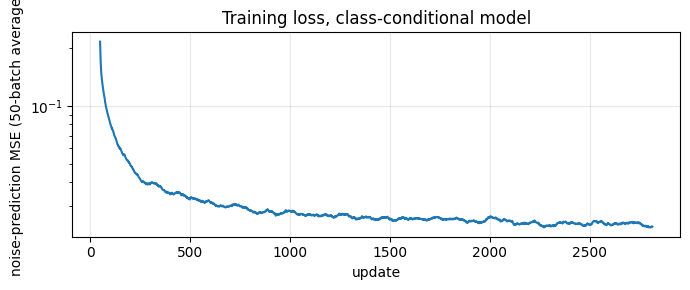

In [35]:
# About 2,800 updates (6 epochs x 469 batches); a few minutes on a Kaggle T4.
EPOCHS = 6
BATCH_SIZE = 128
# Decay of the weight EMA: it averages roughly the last 1 / (1 - 0.999) = 1,000 updates.
EMA_DECAY = 0.999
# AdamW updates the ordinary model only; the EMA copy is never given to the optimizer.
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4)
# The EMA copy starts as an exact copy of the untrained model, in eval mode and without gradients: only ema_update changes it.
ema_model = copy.deepcopy(model).eval().requires_grad_(False)

# losses: one value per update, for the plot below; start: the clock for the timings.
losses, start = [], time.time()
# Training mode. This U-Net has no dropout or BatchNorm, so it behaves the same in both modes; we set it out of good habit.
model.train()
for epoch in range(EPOCHS):
    # A fresh random order of the 60,000 training images in every epoch.
    order = torch.randperm(len(X_train), device=DEVICE)
    # Walk through that order in batches of 128; the last batch is smaller (60,000 = 468 x 128 + 96).
    for i in range(0, len(X_train), BATCH_SIZE):
        idx = order[i:i + BATCH_SIZE]
        # Images (B, 1, 28, 28) and their labels (B,); conditional_loss drops 10% of the labels.
        loss = conditional_loss(model, X_train[idx], y_train[idx])
        # The usual three steps: clear the old gradients, backpropagate, update the weights.
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        # NEW: after every update, move the EMA copy a small step towards the new weights.
        ema_update(ema_model, model, EMA_DECAY)
        # .item() copies the loss to the CPU as a Python float.
        losses.append(loss.item())
    # Mean loss over this epoch's 469 updates.
    print(f"epoch {epoch + 1}: mean loss {sum(losses[-469:]) / 469:.4f}   ({time.time() - start:.0f} s)")
# Evaluation mode for sampling (again, no change in behaviour for this network).
model.eval()

# Smooth the noisy per-batch loss: the mean of every window of 50 consecutive updates (unfold builds the windows).
smooth = torch.tensor(losses).unfold(0, 50, 1).mean(1)
# The first window ends at update 49, so the smoothed curve starts there. The log scale shows the fast early drop and the slow later decline together.
plt.figure(figsize=(7, 3)); plt.plot(range(49, len(losses)), smooth)
plt.yscale("log"); plt.xlabel("update"); plt.ylabel("noise-prediction MSE (50-batch average)"); plt.grid(alpha=0.3)
plt.title("Training loss, class-conditional model"); plt.tight_layout(); plt.show()

**Reading the output.** In our run, the 6 epochs (about 2,800 updates) took 213 s. The mean loss fell from 0.065 in the first epoch to 0.024 in the last, close to Lecture 1's 0.026 after 5 epochs.

The curve looks like Lecture 1's: a fast drop, then a slow decline. The loss alone says nothing about whether the label is being used, because most of the denoising work does not depend on it. To find out, we have to generate.

## 4. Asking for a digit, and classifier-free guidance

Sampling works as in Lecture 1, with the label passed in at every step. In this section we keep the 1,000-step DDPM sampler; Section 5 replaces it with a faster one.

### The problem: the label is only a hint

**At $w = 1$ (plain conditioning) the label is followed loosely, not reliably.** The network was trained to predict noise well *on average*. The label helps with that, but it is one input among several. At high noise levels in particular, the noisy image tells the network almost nothing, and the label changes its prediction only slightly. The result (see the output below, and Section 6) is that some requested 5s come out looking like 3s or 8s.

We want a knob that says "follow the label *more strongly* than the training data alone would". **Classifier-free guidance (CFG)** (Ho & Salimans, 2022) is that knob. It needs no retraining and no extra model, only the "no label" training of Section 2. The cost of CFG is **two network calls per step** instead of one.

### The mechanism in three steps

At every sampling step, with the same noisy image $x_t$ and timestep $t$:

1. **Ask without the label.** $\hat\epsilon_{\text{uncond}} = \epsilon_\theta(x_t, t, \varnothing)$, with $\varnothing$ = label 10, "no label". This is the network's noise prediction for "some digit".
2. **Ask with the label.** $\hat\epsilon_{\text{cond}} = \epsilon_\theta(x_t, t, y)$. This is its prediction for "a 7".
3. **Extrapolate.** The difference $\hat\epsilon_{\text{cond}} - \hat\epsilon_{\text{uncond}}$ is *what knowing the label changed*. Start from the unconditional prediction and apply that change $w$ times:

$$\hat\epsilon = \hat\epsilon_{\text{uncond}} + w\,\big(\hat\epsilon_{\text{cond}} - \hat\epsilon_{\text{uncond}}\big) = (1 - w)\,\hat\epsilon_{\text{uncond}} + w\,\hat\epsilon_{\text{cond}}.$$

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x_t$ | the current noisy images | $(B, 1, 28, 28)$ |
| $y$ | requested digits, 0–9 | $(B,)$ |
| $\hat\epsilon_{\text{cond}}$, $\hat\epsilon_{\text{uncond}}$ | the two noise predictions | $(B, 1, 28, 28)$ each |
| $w$ | guidance scale, a number we choose at sampling time | scalar |
| $\hat\epsilon$ | the guided prediction, used by the sampler exactly where Lecture 1 used $\epsilon_\theta$ | $(B, 1, 28, 28)$ |

The sampler itself is unchanged: CFG only replaces the noise prediction that the DDPM (or, in Section 5, DDIM) update consumes.

**Where the name comes from.** CFG is named in contrast to an earlier method, **classifier guidance** (Dhariwal & Nichol, 2021):

| | Classifier guidance | Classifier-free guidance |
| --- | --- | --- |
| Direction "towards class $y$" | Gradient $\nabla_{x_t} \log p_\phi(y \mid x_t)$ of a **separate classifier** | $\hat\epsilon_{\text{cond}} - \hat\epsilon_{\text{uncond}}$, from the diffusion model itself |
| Extra model | A classifier trained on *noisy* images at every $t$ (an ordinary classifier fails on noise) | None: only the 10% "no label" training |

CFG gets the effect of classifier guidance while being *free* of an explicit classifier.

### What $w$ does: interpolate, then extrapolate

The second form of the formula, $(1-w)\,\hat\epsilon_{\text{uncond}} + w\,\hat\epsilon_{\text{cond}}$, shows that $w$ slides along the line through the two predictions:

```text
            w = 0              w = 1                  w = 2                 w = 4
  ----------●------------------●----------------------●---------------------●------->
     ε̂_uncond           ε̂_cond                beyond ε̂_cond:      far beyond:
   ("some digit")       ("a 7")              "more 7 than a 7"    exaggerated
            |<-- interpolation -->|<------------- extrapolation ------------->|
```

| Guidance scale $w$ | Weights on (uncond, cond) | Effect |
| --- | --- | --- |
| $w = 0$ | (1, 0) | Ignore the label: unconditional generation |
| $0 < w < 1$ | both positive | Weaker than plain conditioning |
| $w = 1$ | (0, 1) | Plain conditional prediction, no extra push |
| $w > 1$ | (negative, $> 1$) | **Extrapolation**: move *away* from "some digit" and past "a 7". More clearly the requested class, usually less varied |

**Small numerical example.** Take one pixel of one image at some step, with $\hat\epsilon_{\text{uncond}} = 0.20$ and $\hat\epsilon_{\text{cond}} = 0.50$. The label's effect is $0.50 - 0.20 = 0.30$.

| $w$ | Computation | Guided $\hat\epsilon$ |
| ---: | --- | ---: |
| 0 | $0.20 + 0 \times 0.30$ | 0.20 |
| 1 | $0.20 + 1 \times 0.30$ | 0.50 |
| 2 | $0.20 + 2 \times 0.30$ | 0.80 |
| 4 | $0.20 + 4 \times 0.30$ | 1.40 |
| 8 | $0.20 + 8 \times 0.30$ | 2.60 |

Two things follow:

- **Where the two predictions agree, guidance does nothing.** If a pixel gets the same prediction with and without the label (background far from any stroke, say), the difference is 0 and every $w$ gives the same value. Guidance acts only where the label matters.
- **Large $w$ produces values the network never produced.** At $w = 8$ the prediction is 2.6, outside the range of either input. Pushed this far, images become over-sharpened, with thick strokes and ragged edges (Section 6 shows this at $w = 8$), and the estimated clean image can leave $[-1, 1]$, which is why the DDIM sampler in Section 5 clips it.

### How one network gives both predictions

There is no separate unconditional network. "No label" is just another label value, 10, with its own learned embedding, and it enters the network exactly like a digit label:

```python
self.label = nn.Embedding(11, 128)        # one learned 128-d vector for each of 0..9, plus 10 = "no label"
e = self.time(t) + self.label(y)          # one embedding per input, added inside every block
```

`guided_eps` stacks two copies of the same noisy images into one batch of $2B$ and gives them different labels:

| Rows of the batch | Images | Timestep | Label | Network output |
| --- | --- | --- | --- | --- |
| $1, \dots, B$ | $x_t$ | $t$ | the requested digits `y`, e.g. 7 | $\hat\epsilon_{\text{cond}}$ |
| $B+1, \dots, 2B$ | $x_t$ (same copy) | $t$ | 10, "no label" | $\hat\epsilon_{\text{uncond}}$ |

Because the images and timestep are identical in both halves, **any difference between the two predictions comes from the label alone**. `.chunk(2)` splits the $(2B, 1, 28, 28)$ output back into the two $(B, 1, 28, 28)$ halves.

**Why stacking is safe.** Every row is processed independently: convolutions act on each image separately, embeddings are per row, and GroupNorm normalises each image on its own. The result equals two separate calls, `net(x, t, y)` and `net(x, t, no_label)`; one larger call is just faster on a GPU. (BatchNorm would break this: it mixes statistics across the batch, so the two halves would affect each other.)

80 digits, 1,000 steps x 2 network passes (guidance): 32.9 s


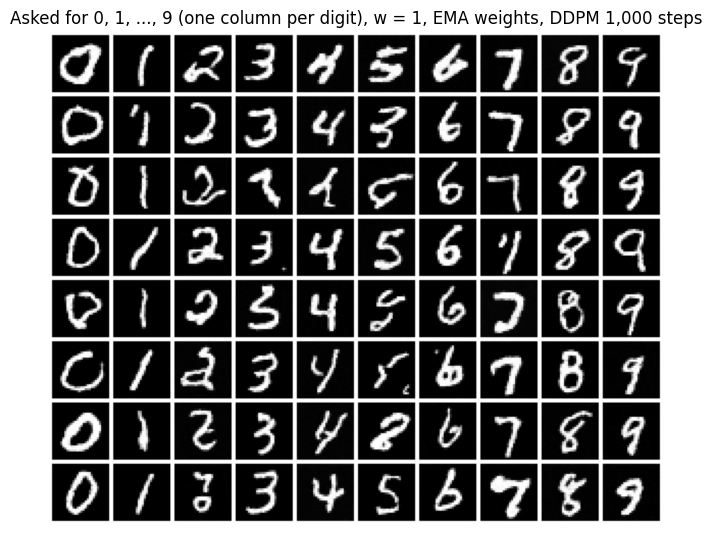

In [ ]:
@torch.no_grad()
def guided_eps(net, x, t, y, w):
    """Noise prediction with classifier-free guidance (CFG).

    Asks the network for its noise prediction twice, once with the requested labels and once with
    the "no label" class NULL_LABEL, and combines the two:
        eps = eps_uncond + w * (eps_cond - eps_uncond)
    Both requests go through the network as one batch of size 2B.

    Args:
        net: noise-prediction network, called as net(x, t, labels). This is the ConditionalUNet model with the EMA weights.
        x:   (B, 1, 28, 28) noisy images at timestep t.
        t:   Python int, the current timestep (the same for every image).
        y:   (B,) requested digit labels, 0-9.
        w:   guidance scale. 0 ignores the label, 1 is the plain conditional prediction,
             > 1 pushes harder towards the requested class.

    Returns:
        (B, 1, 28, 28) guided noise prediction.
    """
    # Batch size: the number of images being denoised.
    B = x.shape[0]
    # The network expects one timestep per input; every input in the doubled batch is at the same step t. Shape: (2B,)
    t_batch = torch.full((2 * B,), t, device=x.device, dtype=torch.long)
    # First half: the requested labels; second half: NULL_LABEL ("no label"), learned from the 10% label dropout in training. Shape: (2B,)
    labels = torch.cat([y, torch.full_like(y, NULL_LABEL)])
    # One forward pass on two copies of x, shape (2B, 1, 28, 28); chunk(2) splits the output back into
    # the conditional prediction (first B) and the unconditional prediction (last B), each (B, 1, 28, 28).
    eps_cond, eps_uncond = net(torch.cat([x, x]), t_batch, labels).chunk(2)
    # CFG: start from the unconditional prediction and move w times along the direction the label adds.
    return eps_uncond + w * (eps_cond - eps_uncond)


@torch.no_grad()
def sample_ddpm(net, y, w=1.0, seed=0):
    """Lecture 1's 1,000-step DDPM sampler, with the label y (B,) and guidance scale w."""
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    x = torch.randn(len(y), 1, 28, 28, device=DEVICE, generator=g)
    for t in reversed(range(T)):
        eps = guided_eps(net, x, t, y, w)
        x = (x - betas[t] / (1 - alpha_bars[t]).sqrt() * eps) / alphas[t].sqrt()
        if t > 0:
            x = x + betas[t].sqrt() * torch.randn(x.shape, device=DEVICE, generator=g)
    return x.clamp(-1, 1)


labels = torch.arange(10, device=DEVICE).repeat_interleave(8)            # 8 samples of each digit 0..9
start = time.time()
ddpm_samples = sample_ddpm(ema_model, labels, w=1.0, seed=0); sync()
print(f"80 digits, 1,000 steps x 2 network passes (guidance): {time.time() - start:.1f} s")
show_grid(ddpm_samples.view(10, 8, 1, 28, 28).transpose(0, 1).reshape(80, 1, 28, 28), nrow=10,
          title="Asked for 0, 1, ..., 9 (one column per digit), w = 1, EMA weights, DDPM 1,000 steps", size=8)

**Reading the output.** Each column was asked for one digit, 0 to 9 from left to right. 80 digits took 32.9 s: 1,000 steps, each a network call on a batch of 160 (80 with labels, 80 without).

In our run most columns hold the requested digit in every row, and the strokes are clean. The misses are a handful of digits that look like a neighbouring class: in the 5 column, one sample looks like a 3 and one like an 8; in the 0 column, one has a stroke through it. Conditioning works, but at $w = 1$ it is not reliable. Section 6 measures how often it fails.

## 5. DDIM: the same network, 50 steps instead of 1,000

DDPM's reverse step only ever moves from $t$ to $t - 1$. **DDIM** (denoising diffusion implicit models; Song, Meng & Ermon, 2020) takes **big jumps** instead. With 50 steps it visits $999 \to 979 \to 958 \to \dots \to 0$: evenly spaced timesteps rounded to whole numbers, so each jump covers 20 or 21 noise levels.

**One DDIM step, from noise level $t$ to the next, lower level $t'$.** Each step uses only the forward equation and its rearrangement for $x_0$ (Lecture 1b, Section 3):

| # | Operation | Formula | In `sample_ddim` below |
| --- | --- | --- | --- |
| 1 | **Predict the noise** in the current sample | $\hat\epsilon = \epsilon_\theta(x_t, t, y)$ | `eps = guided_eps(...)` |
| 2 | **Estimate the clean image** (forward equation solved for $x_0$), clipped to $[-1, 1]$ | $\hat x_0 = \dfrac{x_t - \sqrt{1-\bar\alpha_t}\,\hat\epsilon}{\sqrt{\bar\alpha_t}}$ | `x0_hat = (...).clamp(-1, 1)` |
| 3 | **Recompute the noise** so it matches the clipped $\hat x_0$ | $\hat\epsilon = \dfrac{x_t - \sqrt{\bar\alpha_t}\,\hat x_0}{\sqrt{1-\bar\alpha_t}}$ | `eps = (x - ab.sqrt() * x0_hat) / ...` |
| 4 | **Re-noise to the lower level** $t'$ with the forward equation, reusing $\hat\epsilon$ instead of fresh random noise | $x_{t'} = \sqrt{\bar\alpha_{t'}}\,\hat x_0 + \sqrt{1-\bar\alpha_{t'}}\,\hat\epsilon$ | `x = ab_next.sqrt() * x0_hat + ...` |

**The whole chain for 50 steps:**

```text
x_999 = x_T, pure noise
  t = 999:  predict ε̂ → x̂0 → re-noise → x_979
  t = 979:  predict ε̂ → x̂0 → re-noise → x_958
  ...
  t = 0:    predict ε̂ → x̂0 → return x̂0 as the image (no re-noising)
```

Two points are easy to get wrong:

- **The network is called before each jump, not after.** To build $x_{979}$ the sampler needs an estimate made at $t = 999$, so the first network call is on the pure noise itself.
- **The intermediate samples are constructed, not known.** $x_{979}$ is whatever steps 2 to 4 produced. It is not a noisy version of a real image.

That is the whole sampler (Song et al. call this setting $\eta = 0$). Things to notice:

- **No retraining.** It uses the network trained for DDPM, unchanged. The training loss never involved the 1,000-step chain, only single noise levels, so any sequence of noise levels can be used at sampling time.
- **No fresh noise.** Step 4 reuses the predicted noise, so all the randomness is in the starting noise $x_T$. The same $x_T$ and label always give the same image: DDIM sampling is **deterministic**. DDPM, in contrast, adds fresh noise at every step. 
- **Why big jumps are safe.** Each step re-estimates the clean image from scratch. Early estimates (high $t$) are blurry guesses; as $t$ falls there is less noise to see through, so $\hat x_0$ sharpens, and re-noising to a slightly lower level lets the network correct the previous guess. Nothing relies on the step being tiny. With too few steps, though, each estimate is rough and the result degrades.
- **DDIM does not need guidance.** It only needs some noise prediction $\hat\epsilon$. Here it comes from `guided_eps`, and with $w = 1$ that is just the conditional prediction. Section 7 runs the same sampler on an unconditional model with no guidance.

**DDPM and DDIM side by side.** Both samplers use the same trained network, and both put noise back at every step; they differ in *which* noise. Recall the DDPM step from Lecture 1b and `sample_ddpm` in Section 4:

$$x_{t-1} = \frac{1}{\sqrt{1-\beta_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\hat\epsilon\Big) + \sqrt{\beta_t}\,z, \qquad z \sim \mathcal{N}(0, I).$$

| | DDPM | DDIM ($\eta = 0$) |
| --- | --- | --- |
| Steps | $t \to t-1$, all 1,000 | Big jumps $t \to t'$, e.g. 50 in all |
| Noise removed per step | A small part of $\hat\epsilon$: the coefficient $\beta_t / \sqrt{1-\bar\alpha_t}$ | All of it: the clean image $\hat x_0$ is estimated |
| Noise put back | Fresh random noise $\sqrt{\beta_t}\,z$, unrelated to $\hat\epsilon$ | The predicted $\hat\epsilon$, scaled for level $t'$ |
| Randomness | In $x_T$ **and** at every step | Only in $x_T$ |
| Same $x_T$ and label twice | Different images | The same image |
| Network calls per sample | 1,000 | As many as the steps chosen |

50-step DDIM visits t = [999, 979, 958, 938, 917, 897] ...
80 digits, 50 DDIM steps x 2 network passes: 1.65 s


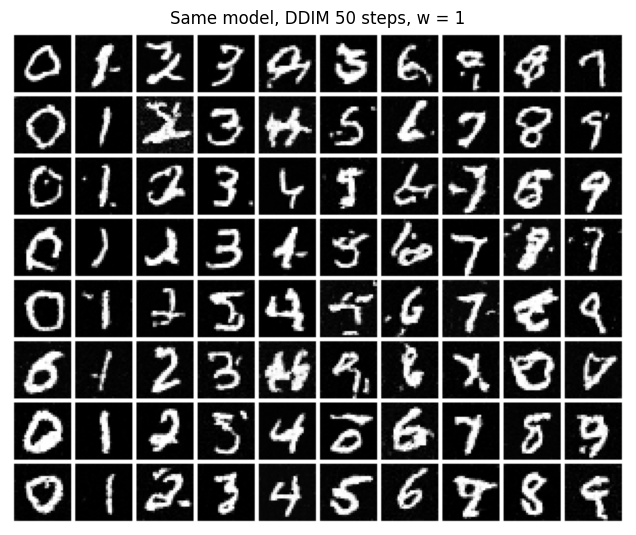

In [ ]:
# Sampling only: no gradients are needed, which saves memory and time.
@torch.no_grad()
def sample_ddim(net, y, steps=50, w=1.0, seed=0, x_T=None):
    """DDIM sampler with eta = 0: deterministic, and far fewer steps than DDPM, using the same trained network.

    Visits `steps` evenly spaced timesteps from T-1 down to 0 (e.g. 999, 979, 958, ..., 0 for 50 steps).
    At each visited level t it predicts the noise, estimates the clean image x0_hat, and re-noises
    x0_hat to the next level t' with the predicted noise (no fresh noise). At t = 0 it returns x0_hat.

    Args:
        net:   noise-prediction network, called through guided_eps as net(x, t, labels)
               (here the ConditionalUNet with EMA weights).
        y:     (B,) requested digit labels, 0-9; one image is generated per label.
        steps: number of timesteps to visit, i.e. network calls per sample. Fewer is faster but rougher.
        w:     classifier-free guidance scale (1 = plain conditional prediction; see guided_eps).
        seed:  seed for the starting noise; used only when x_T is not given.
        x_T:   optional (B, 1, 28, 28) starting noise. Pass it to reuse the same noise across calls,
               e.g. to change only the label or w.

    Returns:
        (B, 1, 28, 28) images in [-1, 1]. The same x_T, y, steps and w always give the same images.
    """
    # No starting noise given: draw it from a seeded generator, so the same seed gives the same x_T.
    if x_T is None:
        # A private random-number generator, so sampling does not disturb the global random state.
        g = torch.Generator(device=DEVICE).manual_seed(seed)
        # Pure noise x_T, one image per requested label: (B, 1, 28, 28).
        x_T = torch.randn(len(y), 1, 28, 28, device=DEVICE, generator=g)
            
    x = x_T
    # The timesteps to visit, evenly spaced and rounded to integers, e.g. [999, 979, 958, ..., 20, 0] for 50 steps.
    ts = torch.linspace(T - 1, 0, steps).round().long().tolist()
    # One DDIM step per visited timestep; i is needed to find the next timestep ts[i + 1].
    for i, t in enumerate(ts):
        # 1. Predict the noise in x at level t (with classifier-free guidance at scale w): (B, 1, 28, 28).
        eps = guided_eps(net, x, t, y, w)
        # alpha_bar at the current level: the share of the clean image's variance still in x.
        ab = alpha_bars[t]
        # 2. Estimate the clean image by solving the forward equation for x_0, then clip it to the image range [-1, 1].
        x0_hat = ((x - (1 - ab).sqrt() * eps) / ab.sqrt()).clamp(-1, 1)
        # At the last timestep (t = 0) there is no lower level to jump to: the estimate is the output.
        if i == len(ts) - 1:
            return x0_hat
        # 3. Recompute the noise so that x0_hat and eps still add up to x after the clipping.
        eps = (x - ab.sqrt() * x0_hat) / (1 - ab).sqrt()
        # alpha_bar at the next, lower noise level t' = ts[i + 1].
        ab_next = alpha_bars[ts[i + 1]]
        # 4. Re-noise to level t' with the forward equation, reusing the predicted noise (no fresh noise).
        x = ab_next.sqrt() * x0_hat + (1 - ab_next).sqrt() * eps


# Show the first six timesteps a 50-step run visits.
print("50-step DDIM visits t =", torch.linspace(T - 1, 0, 50).round().long().tolist()[:6], "...")
# Start the clock.
start = time.time()
# The same 80 requests as the DDPM run in Section 4 (8 of each digit), with the EMA weights and no extra guidance (w = 1).
# sync() waits for the GPU to finish, so the time below is the real sampling time.
ddim_samples = sample_ddim(ema_model, labels, steps=50, w=1.0, seed=0); sync()
# Each step is one network call on a batch of 160 (80 with labels, 80 without).
print(f"80 digits, 50 DDIM steps x 2 network passes: {time.time() - start:.2f} s")
# Samples come ordered by digit (8 zeros, then 8 ones, ...); the reshape puts one digit per column, 0 to 9 left to right.
show_grid(ddim_samples.view(10, 8, 1, 28, 28).transpose(0, 1).reshape(80, 1, 28, 28), nrow=10,
          title="Same model, DDIM 50 steps, w = 1", size=8)

**Reading the output.** The same 80 requests took 1.65 s, against 32.9 s for DDPM: 20 times fewer steps, about 20 times faster. At $w = 1$ the DDIM digits are a little scruffier than the DDPM ones, with stray dots and a few more malformed digits. Section 6 shows that guidance removes most of this.

### How few steps can we get away with?

The next cell generates the same 20 digits (two of each class, same starting noise) with 1,000-step DDPM and with DDIM at 100, 50, 20, 10 and 5 steps, and times each. DDPM and DDIM start from the same $x_T$ but do not give the same images, because DDPM adds fresh noise at every step.

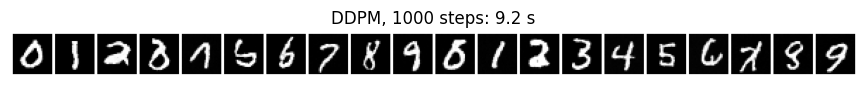

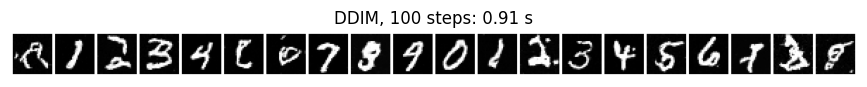

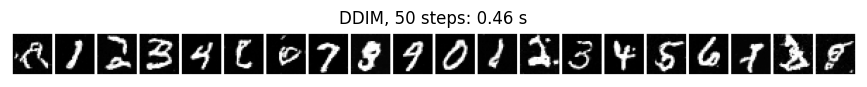

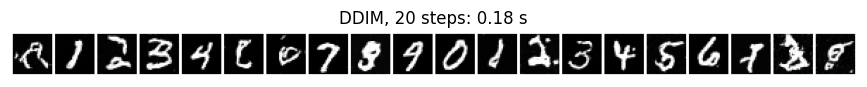

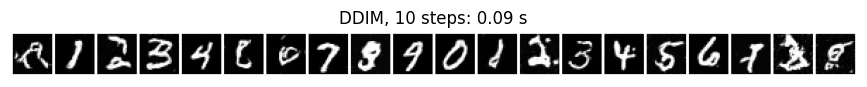

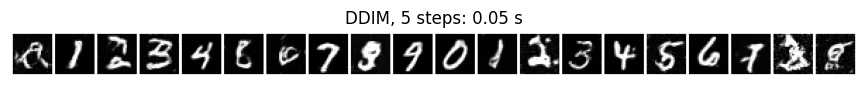

In [38]:
y20 = torch.arange(10, device=DEVICE).repeat(2)
rows, titles = [], []
start = time.time(); rows.append(sample_ddpm(ema_model, y20, w=1.0, seed=3)); sync()
titles.append(f"DDPM, 1000 steps: {time.time() - start:.1f} s")
for k in (100, 50, 20, 10, 5):
    start = time.time(); rows.append(sample_ddim(ema_model, y20, steps=k, w=1.0, seed=3)); sync()
    titles.append(f"DDIM, {k} steps: {time.time() - start:.2f} s")
for r, title in zip(rows, titles):
    show_grid(r, nrow=20, title=title, size=11)

**Reading the output.**

| Sampler | Steps | Time for 20 digits |
| --- | ---: | ---: |
| DDPM | 1,000 | 9.2 s |
| DDIM | 100 | 0.91 s |
| DDIM | 50 | 0.46 s |
| DDIM | 20 | 0.18 s |
| DDIM | 10 | 0.09 s |
| DDIM | 5 | 0.05 s |

- **Time** is proportional to the number of network calls, as expected.
- **The five DDIM rows are almost the same 20 digits.** The sampler is deterministic, so the step count changes how carefully the same path is followed, not which digit is drawn. At 10 and especially 5 steps, the strokes become grainier and a few digits lose detail: each jump relies on a rougher estimate of the clean image.
- **The DDPM row is a different set of digits** from the same starting noise, because DDPM adds fresh noise at every step. Both kinds of row contain a few misses at $w = 1$, but they differ in kind. DDPM's misses are clean strokes that look like a neighbouring digit, such as a 3 that looks like an 8. DDIM's are more often malformed scribbles or blobs.

### Same starting noise, different labels

Because DDIM is deterministic, we can hold the starting noise fixed and change only the label. Each row below uses **one** starting noise $x_T$ and asks for each of the ten digits.

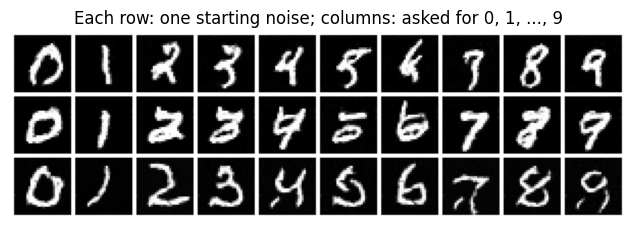

In [39]:
torch.manual_seed(5)
x_T = torch.randn(3, 1, 1, 28, 28, device=DEVICE).expand(3, 10, 1, 28, 28).reshape(30, 1, 28, 28)   # 3 noises, each repeated 10x
y_all = torch.arange(10, device=DEVICE).repeat(3)
same_noise = sample_ddim(ema_model, y_all, steps=50, w=1.0, x_T=x_T)
show_grid(same_noise, nrow=10, title="Each row: one starting noise; columns: asked for 0, 1, ..., 9", size=8)

**Reading the output.** Within a row the digit changes with the label, while the rows differ in **style**. In our run, the first row has thinner strokes, the second has bold, thick strokes throughout, and the third is thinner again with more slant and a few broken digits (the 7 and the 9). The label decides *what* is drawn; the starting noise influences *how*.

### Summary: what DDIM buys

**The main advantage is speed without retraining:** DDIM samples in far fewer steps from the same network trained for DDPM, because training only ever saw single noise levels, never the 1,000-step chain.

| | DDPM | DDIM, 50 steps |
| --- | --- | --- |
| Network calls per sample | 1,000 | 50 |
| Time for 80 digits (our run) | 32.9 s | 1.65 s |
| Retraining needed | — | None |

- **Determinism, a second advantage.** All the randomness is in $x_T$, so the same $x_T$ and label always give the same image. That is what let us change only the label above, and what lets Section 6 change only the guidance scale $w$.
- **The cost: quality at very few steps.** At 10 and especially 5 steps, strokes get grainier and digits lose detail, because each jump relies on a rougher $\hat x_0$. The step count is a choice on a speed–quality curve, not a free saving.

## 6. Measuring fidelity and diversity

"Looks better" is not a measurement. For class-conditional digits we can measure two things that pull against each other:

- **Fidelity to the condition:** is a requested 7 actually a 7? We train a small, separate **classifier** on real MNIST and count how often it agrees with the requested label.
- **Diversity:** do the 7s differ from each other, or are they all the same 7? We use the **average pixel distance between pairs of samples of the same class**, and compare it with the same measure on real test digits.

Both are rough proxies. The classifier is a judge with its own errors (we report its accuracy on real test digits for reference), and it may accept odd-looking digits that happen to match features it relies on. Pixel distance counts any difference, including noise and artefacts, as "diversity".

Published work on natural images uses the **Fréchet Inception distance (FID)** (Heusel et al., 2017). It compares the statistics of features of many generated and real images, extracted by a network pretrained on ImageNet, and reflects fidelity and diversity together (lower is better). We do not compute it here: it needs tens of thousands of samples to be reliable, its features are designed for natural photos rather than digits, and a single number hides *which* of the two properties changed.

In [40]:
class DigitClassifier(nn.Module):
    """A small CNN used only as a measuring instrument. It is independent of the diffusion model."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),        # 28 -> 14
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),       # 14 -> 7
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10))

    def forward(self, x):
        return self.net(x)


torch.manual_seed(SEED)
clf = DigitClassifier().to(DEVICE)
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
clf.train()
for epoch in range(2):
    order = torch.randperm(len(X_train), device=DEVICE)
    for i in range(0, len(X_train), 256):
        idx = order[i:i + 256]
        loss = F.cross_entropy(clf(X_train[idx]), y_train[idx])
        opt.zero_grad(); loss.backward(); opt.step()
clf.eval()


@torch.no_grad()
def class_accuracy(images, requested):
    return (clf(images).argmax(1) == requested).float().mean().item()


@torch.no_grad()
def within_class_diversity(images, labels):
    """Mean pixel (L2) distance between pairs of images with the same label, averaged over labels."""
    per_class = []
    for c in labels.unique():
        group = images[labels == c].flatten(1)
        d = torch.cdist(group, group)
        n = len(group)
        per_class.append(d.sum().item() / (n * (n - 1)))            # mean over pairs, excluding each image with itself
    return sum(per_class) / len(per_class)


print(f"classifier accuracy on real test digits: {class_accuracy(X_test, y_test):.3f}")
real_sub = torch.cat([X_test[y_test == c][:50] for c in range(10)])
real_lab = torch.arange(10, device=DEVICE).repeat_interleave(50)
REAL_DIVERSITY = within_class_diversity(real_sub, real_lab)
print(f"within-class diversity of real test digits (50 per class): {REAL_DIVERSITY:.2f}")

classifier accuracy on real test digits: 0.983
within-class diversity of real test digits (50 per class): 17.52


Now the experiment. We generate 50 digits of each class (500 in all) with DDIM at 50 steps, for several guidance scales, using the **same starting noise** for every setting, so that only $w$ changes. We also run $w = 1$ with the raw (non-EMA) weights, to see what the EMA contributed.

 weights     w   classifier agrees   within-class diversity
     EMA   0.0               0.112                    21.26
     EMA   1.0               0.842                    19.22
     EMA   2.0               0.988                    17.71
     EMA   4.0               1.000                    16.48
     EMA   8.0               0.998                    15.52
     raw   1.0               0.888                    17.97
                  real test digits                    17.52


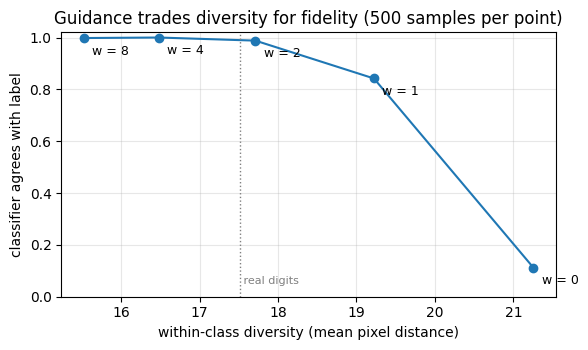

In [41]:
y500 = torch.arange(10, device=DEVICE).repeat_interleave(50)
results, examples = [], {}
for w in (0.0, 1.0, 2.0, 4.0, 8.0):
    imgs = sample_ddim(ema_model, y500, steps=50, w=w, seed=11)
    results.append(("EMA", w, class_accuracy(imgs, y500), within_class_diversity(imgs, y500)))
    examples[w] = imgs
imgs = sample_ddim(model, y500, steps=50, w=1.0, seed=11)
results.append(("raw", 1.0, class_accuracy(imgs, y500), within_class_diversity(imgs, y500)))

print(f"{'weights':>8}{'w':>6}{'classifier agrees':>20}{'within-class diversity':>25}")
for name, w, acc, div in results:
    print(f"{name:>8}{w:>6.1f}{acc:>20.3f}{div:>25.2f}")
print(f"{'real test digits':>34}{'':>3}{REAL_DIVERSITY:>22.2f}")

ema_rows = [r for r in results if r[0] == "EMA"]
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot([r[3] for r in ema_rows], [r[2] for r in ema_rows], "o-")
for _, w, acc, div in ema_rows:
    ax.annotate(f"w = {w:g}", (div, acc), textcoords="offset points", xytext=(6, -12), fontsize=9)
ax.axvline(REAL_DIVERSITY, color="grey", ls=":", lw=1); ax.text(REAL_DIVERSITY, 0.05, " real digits", color="grey", fontsize=8)
ax.set_xlabel("within-class diversity (mean pixel distance)"); ax.set_ylabel("classifier agrees with label")
ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.set_title("Guidance trades diversity for fidelity (500 samples per point)")
plt.tight_layout(); plt.show()

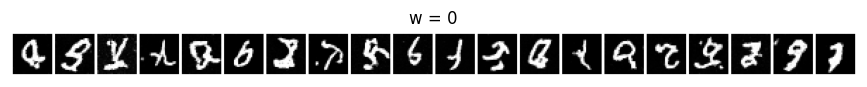

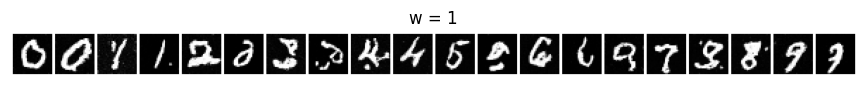

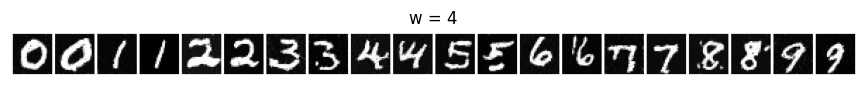

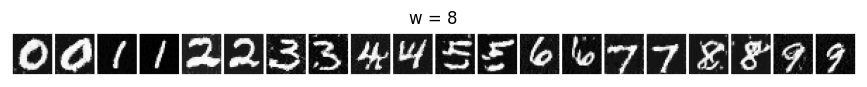

In [42]:
for w in (0.0, 1.0, 4.0, 8.0):
    pick = torch.cat([examples[w][y500 == c][:2] for c in range(10)])          # first two samples of each class
    show_grid(pick, nrow=20, title=f"w = {w:g}", size=11)

**Reading the output.** Our run gave:

| Weights | $w$ | Classifier agrees | Within-class diversity |
| --- | ---: | ---: | ---: |
| EMA | 0 | 0.112 | 21.26 |
| EMA | 1 | 0.842 | 19.22 |
| EMA | 2 | 0.988 | 17.71 |
| EMA | 4 | 1.000 | 16.48 |
| EMA | 8 | 0.998 | 15.52 |
| raw | 1 | 0.888 | 17.97 |
| real test digits | | (0.983 classifier accuracy) | 17.52 |

- **$w = 0$** ignores the label. Agreement is 0.112, about the one-in-ten expected by chance. The example grid shows why: without a label, this small, briefly trained model produces mostly digit-like scribbles. Only 10% of its training saw "no label", so its unconditional model is weak. Its "diversity" of 21.26 is the highest in the table, but much of it is differences between malformed shapes, not variety among good digits: pixel distance counts any difference.
- **As $w$ grows, agreement rises and diversity falls.** Agreement is 0.84 at $w = 1$, 0.99 at $w = 2$, and essentially 1.0 from $w = 4$, while diversity falls steadily from 19.2 to 15.5. In the grids, the $w = 4$ and $w = 8$ digits are clean, bold and very alike: the two samples of each class are nearly the same shape. At $w = 8$ the strokes are thicker and the edges a little ragged. That is the **fidelity–diversity trade-off**.
- **$w = 2$ is the closest to real data on both measures.** Its diversity (17.71) matches real test digits (17.52), and the classifier agrees 98.8% of the time, close to its 98.3% accuracy on real digits. Beyond that, extra guidance buys no fidelity, only sameness. There is no universally best $w$: it depends on whether you need the right class every time or a varied set.
- **EMA did not help in this run.** The raw weights agreed more often (0.888 against 0.842), with diversity closer to real digits. With decay 0.999 the EMA averages roughly the last 1,000 of only 2,800 updates, some of them from when the model was still clearly improving. EMA pays off in long runs where the weights jitter around a solution that has stopped improving. That is how it is used in published models, not in a 3-minute run.

Each point uses 500 samples (50 per class) and one seed. A difference of a few percentage points could change with another seed or another training run; the trend across $w$ is far larger than that.

## 7. DDIM on the published model

In Lecture 1 the published CIFAR-10 DDPM needed 1,000 network calls for 16 images. That model was trained only for DDPM sampling, but, as Section 5 argued, DDIM can use any noise-prediction network trained this way. We run our `sample_ddim` logic on it, with no label and no guidance (the model is unconditional).

> **Download:** the next cell installs `diffusers` if it is missing and downloads `google/ddpm-cifar10-32` (143 MB, Apache-2.0). No Hugging Face account is needed; warnings about unauthenticated requests can be ignored.

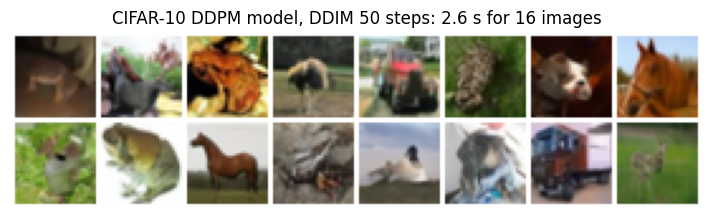

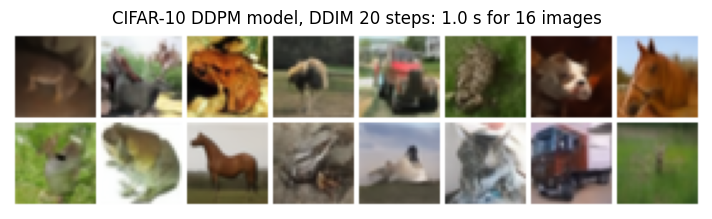

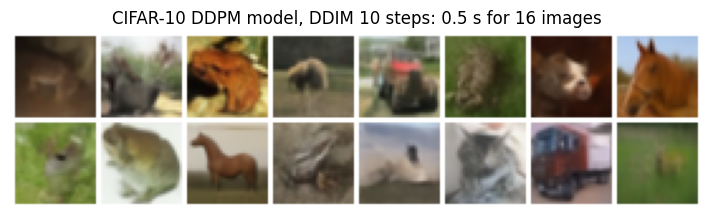

In [43]:
try:
    import diffusers
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "diffusers"])
    import diffusers
from diffusers import UNet2DModel

cifar_unet = UNet2DModel.from_pretrained("google/ddpm-cifar10-32").to(DEVICE).eval()


@torch.no_grad()
def cifar_ddim(n, steps, seed=0):
    """Unconditional DDIM for the CIFAR-10 model: the same two lines per step as sample_ddim, without labels."""
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    x = torch.randn(n, 3, 32, 32, device=DEVICE, generator=g)
    ts = torch.linspace(T - 1, 0, steps).round().long().tolist()
    for i, t in enumerate(ts):
        eps = cifar_unet(x, torch.full((n,), t, device=DEVICE)).sample
        ab = alpha_bars[t]
        x0_hat = ((x - (1 - ab).sqrt() * eps) / ab.sqrt()).clamp(-1, 1)
        if i == len(ts) - 1:
            return x0_hat
        eps = (x - ab.sqrt() * x0_hat) / (1 - ab).sqrt()
        ab_next = alpha_bars[ts[i + 1]]
        x = ab_next.sqrt() * x0_hat + (1 - ab_next).sqrt() * eps


for steps in (50, 20, 10):
    start = time.time(); imgs = cifar_ddim(16, steps, seed=0); sync()
    show_grid(imgs, nrow=8, title=f"CIFAR-10 DDPM model, DDIM {steps} steps: {time.time() - start:.1f} s for 16 images", size=9)

**Reading the output.** Lecture 1's 1,000-step DDPM run of the same model on the same kind of GPU took 56 s for 16 images. In our run DDIM took:

| Steps | Time for 16 images |
| ---: | ---: |
| 50 | 2.6 s |
| 20 | 1.0 s |
| 10 | 0.5 s |

At 50 steps it is about 20 times faster, and the images are recognisable scenes: horses, a frog, a truck, a dog.

Since DDIM is deterministic, the three grids start from the same noise and show the **same 16 images**. Their composition hardly changes as the step count drops, but at 10 steps they are softer and lose fine texture. Lower step counts are a choice on a **speed–quality** curve, not a free saving. Note that the published model, trained far longer, copes with few steps better than our small MNIST model.

## 8. What changed, and where

| Fix | Where it acts | Retrain? | What it buys | What it costs |
| --- | --- | --- | --- | --- |
| Cosine schedule | Forward process | Yes | Fewer steps wasted on pure noise | Retraining; the model is tied to its schedule |
| Class conditioning | Network input | Yes | Ask for a class | Needs labelled data |
| EMA weights | After training | No (kept during training) | Smoother, steadier weights for sampling, in long runs | A second copy of the weights; can lag behind in short runs (Section 6) |
| Classifier-free guidance | Sampling | No (needs the 10% "no label" training) | Samples follow the condition more closely | Less diversity; two network passes per step |
| DDIM | Sampling | No | 20× fewer steps; deterministic | Quality drops when steps get too few |

### Common misconceptions

- **"DDIM is a different model."** It is a different *sampler* for the same trained network.
- **"Guidance makes images better."** It makes them follow the condition more strongly, at the cost of diversity, and too much distorts them.
- **"Bad samples mean a bad model."** They can also mean a bug in the sampler: Section 5 describes one line whose absence looked exactly like a failing model.
- **"The label is what the network predicts."** The label is an input (a condition). The network still predicts noise.
- **"A low training loss means the conditioning works."** The loss hardly depends on the label; only samples, measured against the request, show it.

### Responsible use

- **Conditioning controls what is generated, including what should not be.** The same mechanism that asks for a 7 asks for a particular person or a fake document when the condition is a text prompt (Lecture 3).
- **Guidance narrows output towards the most typical examples of a class.** On data about people, that amplifies stereotypes: strongly guided samples of "a doctor" look like the most common doctors in the training data.
- **An automatic judge is not ground truth.** Our classifier, FID, and similar metrics carry their own biases and blind spots; they support, but do not replace, looking at the samples.

## 9. Summary

| Idea | In one line |
| --- | --- |
| Cosine schedule | Defines $\bar\alpha_t$ so the image fades gradually across all steps; needs retraining |
| Conditioning | Add a learned label embedding to the timestep embedding; the loss is unchanged |
| "No label" training | Replace 10% of labels by a null label, so one network is both conditional and unconditional |
| EMA | Sample from a running average of the weights, $\theta_{\text{EMA}} \leftarrow d\,\theta_{\text{EMA}} + (1-d)\,\theta$; it pays off in long runs |
| Classifier-free guidance | $\hat\epsilon = \hat\epsilon_{\text{uncond}} + w(\hat\epsilon_{\text{cond}} - \hat\epsilon_{\text{uncond}})$; larger $w$: more faithful, less varied |
| DDIM | Estimate $\hat x_0$, re-noise it to a lower level with $\hat\epsilon$; any step count, same network, deterministic |
| Measuring | A classifier for fidelity, within-class distance for diversity; FID for natural images, with care |

**Next lecture:** latent diffusion. Run the same process in the compressed latent space of an autoencoder rather than on pixels, and replace the class label with a text prompt: the design of Stable Diffusion.

## 10. Check your understanding

1. The linear schedule's image weight falls below 0.1 at about $t = 673$. Why does that waste steps? What does the cosine schedule change, and why does changing it require retraining?
2. In the conditional model, is the class label an input or a target? What is the training loss, and how does the label affect it?
3. Why are 10% of labels replaced by "no label" during training? What would go wrong with guidance if they were not?
4. Write the guidance formula. What do $w = 0$ and $w = 1$ give? What do you expect to happen to fidelity and diversity as $w$ grows? Use your measurements from Section 6.
5. Describe one DDIM step in words. Why can DDIM use a network trained for DDPM without retraining?
6. DDIM with the same starting noise always gives the same image. DDPM does not. Which part of each sampler explains the difference?
7. Why do we sample from the EMA weights but train the ordinary weights? In Section 6 the raw weights did slightly better than the EMA. Why is that plausible for this run, and what would you change to make the EMA useful?
8. Why is the classifier's agreement with the requested label only a proxy for quality? Give one way it could be fooled.
9. **Exercise.** Change the training schedule to cosine (replace `betas`, `alphas` and `alpha_bars` in Section 3 using `cosine_alpha_bars`), retrain, and repeat the step-count comparison of Section 5. Remember that the published CIFAR-10 model in Section 7 still needs the linear schedule.

## References

- Dhariwal, P., & Nichol, A. (2021). Diffusion models beat GANs on image synthesis. *NeurIPS 2021*. [arXiv:2105.05233](https://arxiv.org/abs/2105.05233)
- Heusel, M., Ramsauer, H., Unterthiner, T., Nessler, B., & Hochreiter, S. (2017). GANs trained by a two time-scale update rule converge to a local Nash equilibrium (introduces FID). *NeurIPS 2017*. [arXiv:1706.08500](https://arxiv.org/abs/1706.08500)
- Ho, J., Jain, A., & Abbeel, P. (2020). Denoising diffusion probabilistic models. *NeurIPS 2020*. [arXiv:2006.11239](https://arxiv.org/abs/2006.11239) · weights: [`google/ddpm-cifar10-32`](https://huggingface.co/google/ddpm-cifar10-32)
- Ho, J., & Salimans, T. (2022). Classifier-free diffusion guidance. [arXiv:2207.12598](https://arxiv.org/abs/2207.12598) (first presented at the NeurIPS 2021 Workshop on Deep Generative Models).
- Nichol, A., & Dhariwal, P. (2021). Improved denoising diffusion probabilistic models. *ICML 2021*. [arXiv:2102.09672](https://arxiv.org/abs/2102.09672)
- Song, J., Meng, C., & Ermon, S. (2020). Denoising diffusion implicit models. *ICLR 2021*. [arXiv:2010.02502](https://arxiv.org/abs/2010.02502)
- LeCun, Y., Cortes, C., & Burges, C. J. C. The MNIST database of handwritten digits.